# Project 2: Housing Price Prediction – Pass 01

## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

Statement:

We want to predict housing sale prices based on various correlated feature data. This is a *supervised regression* problem, where the target of the prediction is sales prices. To accomplish this, we use a regression model alongside Regression prediction techniques, as well as feature scaling and regularization to minimize the RMS percentage error.

## Data Collection/Sources


Data Collection describes the process by which we obtain the data for use in the project. In this case, our data comes from S3 storage buckets on AWS, which we load into memory (variables) via URLs by passing them to the read_csv function of the pandas python library (more on that soon).

The data comes in one large set containing the full data available for use in the project. It is supplemented by a data dictionary that describes the set, the data types of the included data, and other information relevant to its use.

Finally, to store the data in a form we can work with in memory, we use a storage structure called a DataFrame object from the pandas python library. This object allows us to quickly view the data and preview operations on the data without changing it, as well as make updates to the data in a highly intuitive way.

Load Pandas, Numpy, and Matplotlib modules

In [175]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics

from sklearn.preprocessing import LabelEncoder

Load data Train.csv from AWS S3:

In [176]:
# url
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

Next, make a preview DataFrame to look at columns:

In [177]:
# make preview
df_preview = pd.read_csv(url)
df_preview

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000


In [178]:
# preview all column names
df_preview.columns

Index(['PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street',
       'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config',
       'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Overall Qual', 'Overall Cond', 'Year Built',
       'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2',
       'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air',
       'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual',
       'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu',
       'Garage Type', 'Garage Yr Blt', 'Garage Finish'

Define the target column (and features types, if required):

In [179]:
# define target column (by name) and features column(s)
target_col = "SalePrice"
feature_types = ['O']

Create list of target col and feature cols:

In [180]:
# use list comprehension to generate list of target col + selected feature cols
selected_cols = [
    col
    for col in df_preview.columns
    if df_preview[col].dtype in feature_types
]
selected_cols



['MS Zoning',
 'Street',
 'Alley',
 'Lot Shape',
 'Land Contour',
 'Utilities',
 'Lot Config',
 'Land Slope',
 'Neighborhood',
 'Condition 1',
 'Condition 2',
 'Bldg Type',
 'House Style',
 'Roof Style',
 'Roof Matl',
 'Exterior 1st',
 'Exterior 2nd',
 'Mas Vnr Type',
 'Exter Qual',
 'Exter Cond',
 'Foundation',
 'Bsmt Qual',
 'Bsmt Cond',
 'Bsmt Exposure',
 'BsmtFin Type 1',
 'BsmtFin Type 2',
 'Heating',
 'Heating QC',
 'Central Air',
 'Electrical',
 'Kitchen Qual',
 'Functional',
 'Fireplace Qu',
 'Garage Type',
 'Garage Finish',
 'Garage Qual',
 'Garage Cond',
 'Paved Drive',
 'Pool QC',
 'Fence',
 'Misc Feature',
 'Sale Type',
 'Sale Condition']

Read in the data from .csv using target_col and feature_types:

In [181]:
df_preview[selected_cols].dtypes.unique()

array([dtype('O')], dtype=object)

In [182]:
# make dataframe
df = pd.read_csv( url, usecols=selected_cols+[target_col] )

Finally, check the dataframe:

In [183]:
# check dataframe
df

,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition,SalePrice
0,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,...,Unf,TA,TA,N,NaN,MnPrv,NaN,WD,Normal,115400
1,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,...,Unf,TA,TA,Y,NaN,NaN,Shed,WD,Normal,90000
2,RM,Pave,NaN,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,...,Unf,TA,TA,P,NaN,NaN,NaN,WD,Normal,141000
3,FV,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal,254000
4,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,...,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,RM,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,...,Unf,TA,TA,Y,NaN,MnPrv,Shed,WD,Normal,114500
2633,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,...,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Normal,162000
2634,RL,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,...,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal,211500
2635,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal,165000


## Data Cleaning


Data Cleaning is the process of preparing the data set for use in analysis. Many data sets contain bad or null (empty) values, which can cause errors when trying to work with the data and use it in code. Cleaning the data involves removing bad (null-containing) columns and/or rows from the set, as well as imputing (replacing via insertion) similar data into fields with missing or unusable values.

Here, to clean the data, we mostly use the pandas drop function included with pandas DataFrame objects, which allow us to drop columns and rows according to conditions we specify, much like SQL WHERE clauses.

#### Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



First, define the target column:

In [184]:
# check target_col
target_col

'SalePrice'

- head

In [185]:
# head
df.head()

,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition,SalePrice
0,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,...,Unf,TA,TA,N,NaN,MnPrv,NaN,WD,Normal,115400
1,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,...,Unf,TA,TA,Y,NaN,NaN,Shed,WD,Normal,90000
2,RM,Pave,NaN,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,...,Unf,TA,TA,P,NaN,NaN,NaN,WD,Normal,141000
3,FV,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal,254000
4,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,...,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal,155000


- tail

In [186]:
# tail
df.tail()

,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition,SalePrice
2632,RM,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,...,Unf,TA,TA,Y,NaN,MnPrv,Shed,WD,Normal,114500
2633,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,...,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Normal,162000
2634,RL,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,...,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal,211500
2635,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal,165000
2636,RL,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,Gilbert,RRAn,...,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal,225000


- shape

In [187]:
# shape
df.shape

(2637, 44)

- size

In [188]:
# size
df.size

116028

- info

In [189]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 44 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   MS Zoning       2637 non-null   object
 1   Street          2637 non-null   object
 2   Alley           180 non-null    object
 3   Lot Shape       2637 non-null   object
 4   Land Contour    2637 non-null   object
 5   Utilities       2637 non-null   object
 6   Lot Config      2637 non-null   object
 7   Land Slope      2637 non-null   object
 8   Neighborhood    2637 non-null   object
 9   Condition 1     2637 non-null   object
 10  Condition 2     2637 non-null   object
 11  Bldg Type       2637 non-null   object
 12  House Style     2637 non-null   object
 13  Roof Style      2637 non-null   object
 14  Roof Matl       2637 non-null   object
 15  Exterior 1st    2637 non-null   object
 16  Exterior 2nd    2637 non-null   object
 17  Mas Vnr Type    1030 non-null   object
 18  Exter Qu

- describe

In [190]:
# describe
df.describe()

,SalePrice
count,2637.000000
mean,179986.230186
std,78309.251522
min,12789.000000
25%,129500.000000
50%,160000.000000
75%,213000.000000
max,745000.000000


- nunique

In [191]:
# nunique
df.nunique().sort_values( ascending = False )

,0
SalePrice,983
Neighborhood,28
Exterior 2nd,17
Exterior 1st,16
Sale Type,10
Condition 1,9
Functional,8
Roof Matl,8
Condition 2,8
House Style,8


In [192]:
# normalize to look for ID column(s)
df.nunique().sort_values( ascending = False ) / df.shape[0] * 100

,0
SalePrice,37.277209
Neighborhood,1.061813
Exterior 2nd,0.644672
Exterior 1st,0.606750
Sale Type,0.379219
Condition 1,0.341297
Functional,0.303375
Roof Matl,0.303375
Condition 2,0.303375
House Style,0.303375


- unique

In [193]:
# unique
df[target_col].unique()

array([115400,  90000, 141000, 254000, 155000, 125000, 194500, 185000,
       235000, 152000, 201000, 207000, 192000, 174000, 190000, 176000,
       384500, 395039, 167000, 165000, 195000, 104500, 161000, 245700,
       226001, 153500, 139000,  35000, 181000, 212000, 156000, 139500,
       225000,  12789, 157500, 110000, 130000, 263000, 205000, 117000,
       200624, 120000, 137900, 245500, 107000, 327000,  93000, 145250,
       168000, 169900, 122000, 161750, 188000, 149500, 421250, 305000,
        50138, 136000, 150750, 307000, 241000,  86900, 202500,  93500,
       121000, 107500, 336000, 213000, 129000, 170000, 337500, 535000,
       173500, 162000,  37900, 158500,  94000, 350000, 140000, 409900,
       115000, 177000,  94750, 121600, 128500, 301000, 230000, 151000,
       137500,  85500, 129400, 191500, 250000, 135000, 119000, 150000,
       178000, 163900, 199000, 203000, 178900, 180000, 182000, 177900,
       122500, 134900, 132000, 147983,  68500, 158000, 260261,  64500,
      

- isnull

In [194]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Fence,2109
Mas Vnr Type,1607
Fireplace Qu,1284
Garage Qual,147
Garage Finish,147
Garage Cond,147
Garage Type,145


In [195]:
# percent null by column
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
Pool QC,99.582859
Misc Feature,96.359499
Alley,93.174061
Fence,79.977247
Mas Vnr Type,60.940463
Fireplace Qu,48.691695
Garage Qual,5.574516
Garage Finish,5.574516
Garage Cond,5.574516
Garage Type,5.498673


In [196]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100).unique()

array([99.58285931, 96.35949943, 93.17406143, 79.97724687, 60.94046265,
       48.69169511,  5.5745165 ,  5.49867273,  2.88206295,  2.80621919,
        2.76829731,  0.        ])

In [197]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(13579)

In [198]:
# how many rows with at least one null
num_rows_with_nulls = df.isna().any(axis=1).sum()
int(num_rows_with_nulls)

2637

The target (SalePrice) contains no nulls, but the feature (Lot Frontage) contains about 17% null values. To address this, we can impute values using the median value in that column.

- dtypes

In [199]:
# dtypes
df.dtypes

,0
MS Zoning,object
Street,object
Alley,object
Lot Shape,object
Land Contour,object
Utilities,object
Lot Config,object
Land Slope,object
Neighborhood,object
Condition 1,object


Examine null columns, columns with some nulls, and columns with no nulls:

In [200]:
# display columns with all null values
df.isnull().sum()[df.isnull().sum() == df.shape[0]]

,0


In [201]:
# count these
int(df.isnull().sum()[df.isnull().sum() == df.shape[0]].count())

0

In [202]:
# show columns with some null values
df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].sort_values( ascending = False )

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Fence,2109
Mas Vnr Type,1607
Fireplace Qu,1284
Garage Finish,147
Garage Cond,147
Garage Qual,147
Garage Type,145


In [203]:
# count these
int(df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].count())

15

In [204]:
# columns with no nulls
df.isnull().sum()[df.isnull().sum() == 0]

,0
MS Zoning,0
Street,0
Lot Shape,0
Land Contour,0
Utilities,0
Lot Config,0
Land Slope,0
Neighborhood,0
Condition 1,0
Condition 2,0


In [205]:
# count these
int(df.isnull().sum()[df.isnull().sum() == 0].count())

29

#### Target: Value Counts

In [206]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [207]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
SalePrice,
140000,1.175578
135000,1.137656
130000,1.061813
155000,0.910125
160000,0.834281
...,...
160200,0.037922
174190,0.037922
415298,0.037922


In [208]:
# target col size/shape
df[[target_col]].shape[0]

2637

In [209]:
# sum of nulls in target
int(df[[target_col]].isnull().sum().iloc[0])

0

In [210]:
# sum of non-nulls in target
df[[target_col]].shape[0] - int(df[[target_col]].isnull().sum().iloc[0])

2637

There are no nulls in the target column, which means no rows will need to be dropped on its account.

In [211]:
df.shape, df.size

((2637, 44), 116028)

In [212]:
df.drop(columns = [target_col]).columns

Index(['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour',
       'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
       'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC',
       'Central Air', 'Electrical', 'Kitchen Qual', 'Functional',
       'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual',
       'Garage Cond', 'Paved Drive', 'Pool QC', 'Fence', 'Misc Feature',
       'Sale Type', 'Sale Condition'],
      dtype='object')

In [213]:
df.isna().any(axis=1).sum()

np.int64(2637)

#### Summary:

This abridged dataset contains 2637 rows and 2 columns, making for a total of 5274 entries of data. Many of these fields are null.

Details:

  - target column: 'SalePrice'
  - feature columns: [
  'MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour',
       'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
       'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC',
       'Central Air', 'Electrical', 'Kitchen Qual', 'Functional',
       'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual',
       'Garage Cond', 'Paved Drive', 'Pool QC', 'Fence', 'Misc Feature',
       'Sale Type', 'Sale Condition'
  ]
  - identifier columns: n/a
  - null columns: 0
  - null rows (target): 0
  - null rows (any): 2637 / 2637 (~100%)

#### If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


In [214]:
# head again to double-check
df.head()

,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition,SalePrice
0,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,...,Unf,TA,TA,N,NaN,MnPrv,NaN,WD,Normal,115400
1,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,...,Unf,TA,TA,Y,NaN,NaN,Shed,WD,Normal,90000
2,RM,Pave,NaN,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,...,Unf,TA,TA,P,NaN,NaN,NaN,WD,Normal,141000
3,FV,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal,254000
4,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,...,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal,155000


In [215]:
# make backup
df_bak = df.copy()
df_bak

,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition,SalePrice
0,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,...,Unf,TA,TA,N,NaN,MnPrv,NaN,WD,Normal,115400
1,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,...,Unf,TA,TA,Y,NaN,NaN,Shed,WD,Normal,90000
2,RM,Pave,NaN,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,...,Unf,TA,TA,P,NaN,NaN,NaN,WD,Normal,141000
3,FV,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal,254000
4,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,...,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,RM,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,...,Unf,TA,TA,Y,NaN,MnPrv,Shed,WD,Normal,114500
2633,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,...,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Normal,162000
2634,RL,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,...,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal,211500
2635,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal,165000


In [216]:
# restore from backup
df = df_bak.copy()
df

,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition,SalePrice
0,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,...,Unf,TA,TA,N,NaN,MnPrv,NaN,WD,Normal,115400
1,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,...,Unf,TA,TA,Y,NaN,NaN,Shed,WD,Normal,90000
2,RM,Pave,NaN,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,...,Unf,TA,TA,P,NaN,NaN,NaN,WD,Normal,141000
3,FV,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal,254000
4,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,...,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,RM,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,...,Unf,TA,TA,Y,NaN,MnPrv,Shed,WD,Normal,114500
2633,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,...,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Normal,162000
2634,RL,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,...,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal,211500
2635,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal,165000


In [217]:
# Setup drop thresholds

# Drop a column if null % above 85%
drop_column_threshold = 0.85

# Drop a row if null % below 15%
drop_row_threshold = 0.15

1. Remove identifier columns

- No identifier rows present in set (culled at read level)

2. Drop null target rows



- No null target rows

3. Drop feature columns with many or all nulls

In [218]:
# Select columns where the missing value ratio is less than drop_column_threshold
high_nulls = df.columns[df.isnull().mean() > drop_column_threshold]
high_nulls

Index(['Alley', 'Pool QC', 'Misc Feature'], dtype='object')

In [219]:
# Drop those specific columns
df = df.drop(columns=high_nulls)
df

,MS Zoning,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,...,Fireplace Qu,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Fence,Sale Type,Sale Condition,SalePrice
0,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,Norm,...,NaN,Detchd,Unf,TA,TA,N,MnPrv,WD,Normal,115400
1,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,Norm,...,NaN,CarPort,Unf,TA,TA,Y,NaN,WD,Normal,90000
2,RM,Pave,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,...,Gd,Detchd,Unf,TA,TA,P,NaN,WD,Normal,141000
3,FV,Pave,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,...,TA,Attchd,RFn,TA,TA,Y,NaN,WD,Normal,254000
4,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,Norm,...,NaN,Detchd,RFn,TA,TA,Y,MnPrv,WD,Normal,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,RM,Pave,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,Norm,...,Gd,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal,114500
2633,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,Norm,...,NaN,Attchd,Unf,TA,TA,Y,NaN,WD,Normal,162000
2634,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,Norm,...,TA,Attchd,Fin,TA,TA,Y,NaN,WD,Normal,211500
2635,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,Norm,...,TA,Attchd,RFn,TA,TA,Y,MnPrv,WD,Normal,165000


In [220]:
# backup 2
df_bak2 = df.copy()

In [221]:
# restore from backup 2
df = df_bak2.copy()

In [222]:
df

,MS Zoning,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,...,Fireplace Qu,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Fence,Sale Type,Sale Condition,SalePrice
0,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,Norm,...,NaN,Detchd,Unf,TA,TA,N,MnPrv,WD,Normal,115400
1,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,Norm,...,NaN,CarPort,Unf,TA,TA,Y,NaN,WD,Normal,90000
2,RM,Pave,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,...,Gd,Detchd,Unf,TA,TA,P,NaN,WD,Normal,141000
3,FV,Pave,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,...,TA,Attchd,RFn,TA,TA,Y,NaN,WD,Normal,254000
4,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,Norm,...,NaN,Detchd,RFn,TA,TA,Y,MnPrv,WD,Normal,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,RM,Pave,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,Norm,...,Gd,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal,114500
2633,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,Norm,...,NaN,Attchd,Unf,TA,TA,Y,NaN,WD,Normal,162000
2634,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,Norm,...,TA,Attchd,Fin,TA,TA,Y,NaN,WD,Normal,211500
2635,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,Norm,...,TA,Attchd,RFn,TA,TA,Y,MnPrv,WD,Normal,165000


4. Drop remaining records with null counts (if few)

In [223]:
# Select columns where the missing value ratio is less than drop_column_threshold
low_nulls = df.columns[df.isnull().mean() < drop_row_threshold]
low_nulls

Index(['MS Zoning', 'Street', 'Lot Shape', 'Land Contour', 'Utilities',
       'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
       'Exterior 1st', 'Exterior 2nd', 'Exter Qual', 'Exter Cond',
       'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC',
       'Central Air', 'Electrical', 'Kitchen Qual', 'Functional',
       'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond',
       'Paved Drive', 'Sale Type', 'Sale Condition', 'SalePrice'],
      dtype='object')

In [224]:
# Drop those specific columns
df = df.dropna(subset=low_nulls)
df

,MS Zoning,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,...,Fireplace Qu,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Fence,Sale Type,Sale Condition,SalePrice
0,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,Norm,...,NaN,Detchd,Unf,TA,TA,N,MnPrv,WD,Normal,115400
2,RM,Pave,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,...,Gd,Detchd,Unf,TA,TA,P,NaN,WD,Normal,141000
3,FV,Pave,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,...,TA,Attchd,RFn,TA,TA,Y,NaN,WD,Normal,254000
4,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,Norm,...,NaN,Detchd,RFn,TA,TA,Y,MnPrv,WD,Normal,155000
5,RL,Pave,Reg,Lvl,AllPub,FR2,Gtl,Sawyer,Feedr,Norm,...,Fa,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal,125000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,RM,Pave,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,Norm,...,Gd,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal,114500
2633,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,Norm,...,NaN,Attchd,Unf,TA,TA,Y,NaN,WD,Normal,162000
2634,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,Norm,...,TA,Attchd,Fin,TA,TA,Y,NaN,WD,Normal,211500
2635,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,Norm,...,TA,Attchd,RFn,TA,TA,Y,MnPrv,WD,Normal,165000


In [225]:
# backup 3
df_bak3 = df.copy()

In [226]:
# restore from backup 3
df = df_bak3.copy()

5.  Impute with the median for remaining fields

In [227]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
Fence,1937
Mas Vnr Type,1420
Fireplace Qu,1108
Street,0
Utilities,0
Lot Config,0
Lot Shape,0
Land Contour,0
MS Zoning,0
Condition 1,0


Impute:

In [228]:
# Get list of feature cols
feature_cols = list(df.drop(columns = target_col).columns)

# Loop through feature cols to bulk impute
for feature_col in feature_cols:

  # Assign mode to nulls
  mode = df[feature_col].mode(dropna = True)[0]
  df.fillna( {feature_col: mode}, inplace = True )

In [229]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
MS Zoning,0
Street,0
Lot Shape,0
Land Contour,0
Utilities,0
Lot Config,0
Land Slope,0
Neighborhood,0
Condition 1,0
Condition 2,0


In [230]:
# backup 4
df_bak4 = df.copy()

In [231]:
# restore from backup 4
df = df_bak4.copy()

In [232]:
df

,MS Zoning,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,...,Fireplace Qu,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Fence,Sale Type,Sale Condition,SalePrice
0,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,Norm,...,Gd,Detchd,Unf,TA,TA,N,MnPrv,WD,Normal,115400
2,RM,Pave,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,...,Gd,Detchd,Unf,TA,TA,P,MnPrv,WD,Normal,141000
3,FV,Pave,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,...,TA,Attchd,RFn,TA,TA,Y,MnPrv,WD,Normal,254000
4,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,Norm,...,Gd,Detchd,RFn,TA,TA,Y,MnPrv,WD,Normal,155000
5,RL,Pave,Reg,Lvl,AllPub,FR2,Gtl,Sawyer,Feedr,Norm,...,Fa,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal,125000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,RM,Pave,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,Norm,...,Gd,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal,114500
2633,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,Norm,...,Gd,Attchd,Unf,TA,TA,Y,MnPrv,WD,Normal,162000
2634,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,Norm,...,TA,Attchd,Fin,TA,TA,Y,MnPrv,WD,Normal,211500
2635,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,Norm,...,TA,Attchd,RFn,TA,TA,Y,MnPrv,WD,Normal,165000


In [233]:
# check total null counts sum
f"Number of remaining nulls in df: {int(df.isnull().sum().sum())}"

'Number of remaining nulls in df: 0'

## Exploratory Data Analysis


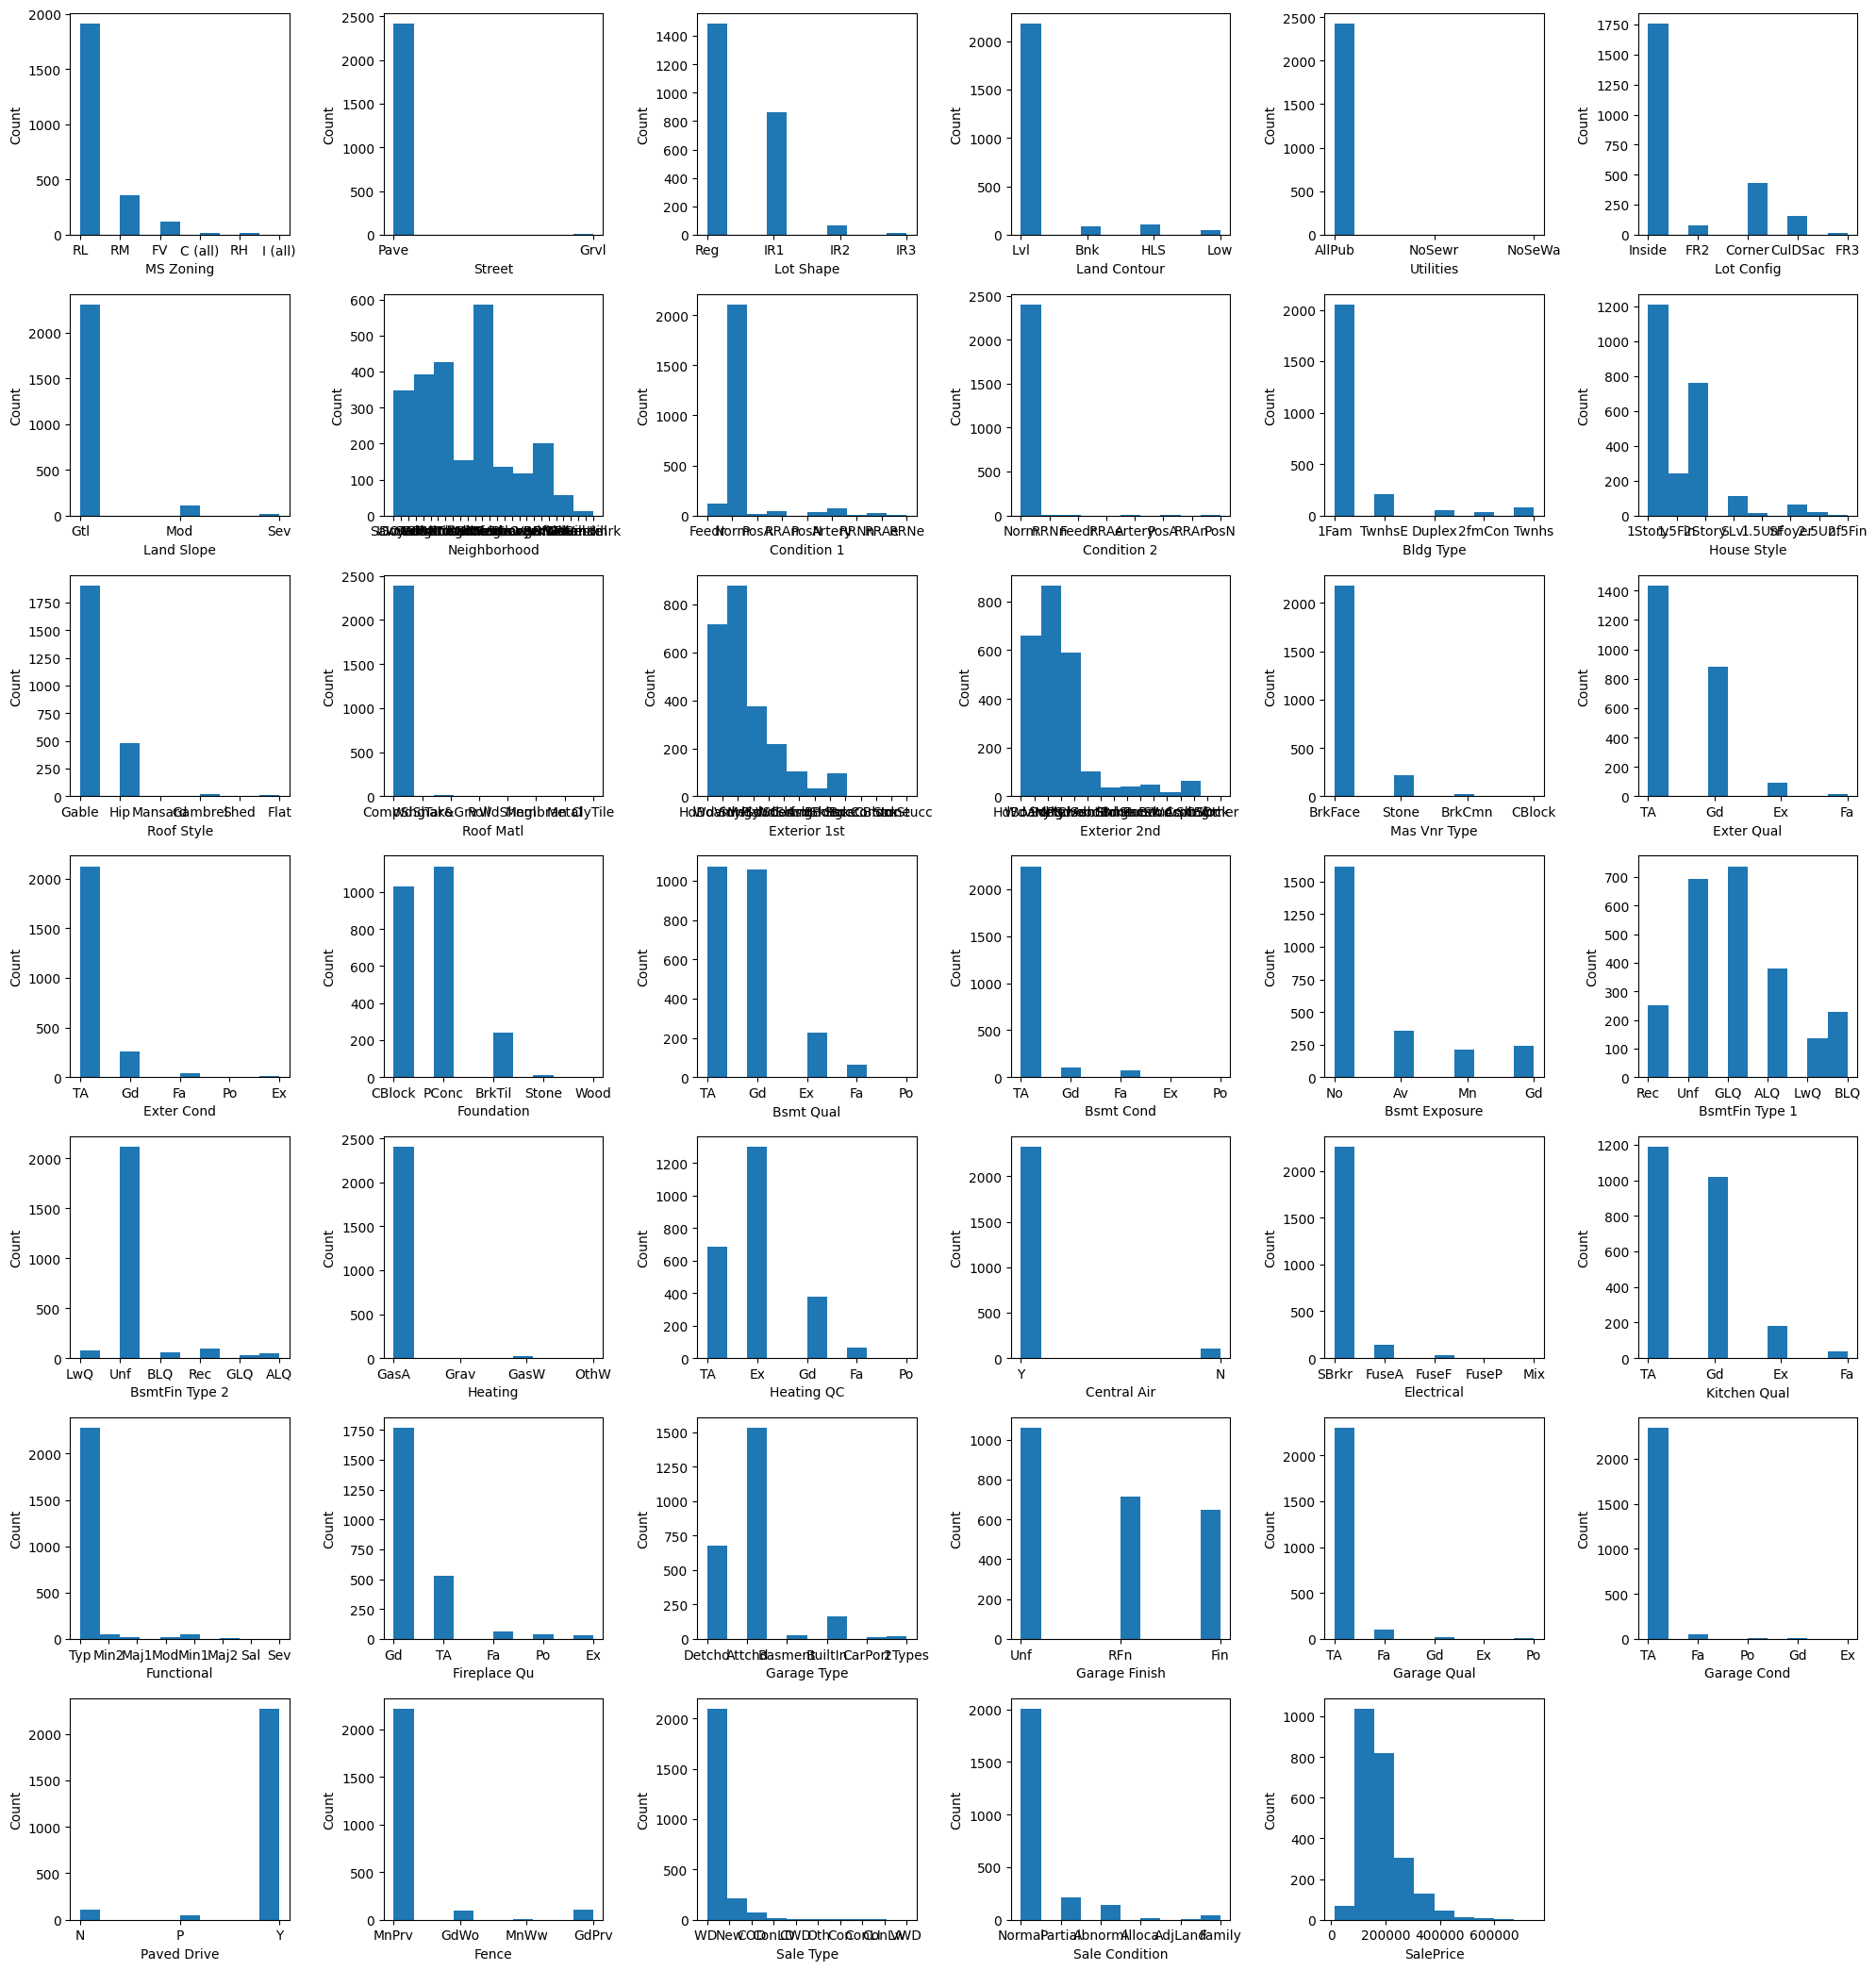

In [234]:
# Let's plot mpg and all of our predictors
num_cols = 6
num_features = len(df.columns)
num_rows = num_features // num_cols + 1
column_names = df.columns

fig, axs = plt.subplots(len(column_names) // 6 + 1,6, figsize=(20, 3*num_rows)) # Creating 2x4 subplots because we have 8 columns in our data

subplots = axs.flatten()
for n, column_name in enumerate(column_names): # Loop through rows
    subplots[n].hist(df[column_name])
    subplots[n].set_xlabel(column_name)
    subplots[n].set_ylabel('Count')

for i in range(num_features, len(subplots)):
    fig.delaxes(subplots[i])

plt.tight_layout()
plt.show()

### What do we notice?

- A few of the features — Exterior 1st, Exterior 2nd, House Style, and perhaps Neighborhood — all appear to trend with SalePrice, with all resembling positively-skewed normal distributions
- Perhaps some outliers in the columns

#### Next, we encode the object features in order to look at correlations:

In [235]:
# Assign numerical values and store in another column
df_encoded = pd.DataFrame(df[target_col])
for feature in feature_cols:
  df_feature = pd.get_dummies(
      pd.DataFrame(df[feature]),
      columns=[feature],
      prefix=feature,
      prefix_sep="_",
      dtype="int"
      )

  df_encoded = pd.concat([df_encoded, df_feature], axis=1, ignore_index=False)

df_encoded

,SalePrice,MS Zoning_C (all),MS Zoning_FV,MS Zoning_I (all),MS Zoning_RH,MS Zoning_RL,MS Zoning_RM,Street_Grvl,Street_Pave,Lot Shape_IR1,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,115400,0,0,0,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
2,141000,0,0,0,0,0,1,0,1,0,...,0,0,0,1,0,0,0,0,1,0
3,254000,0,1,0,0,0,0,0,1,1,...,0,0,0,1,0,0,0,0,1,0
4,155000,0,0,0,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
5,125000,0,0,0,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,0,0,0,0,0,1,0,1,0,...,0,0,0,1,0,0,0,0,1,0
2633,162000,0,0,0,0,1,0,0,1,1,...,0,0,0,1,0,0,0,0,1,0
2634,211500,0,0,0,0,1,0,0,1,1,...,0,0,0,1,0,0,0,0,1,0
2635,165000,0,0,0,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0


In [236]:
# update df
df = df_encoded.copy()

In [237]:
# backup 5
df_bak5 = df.copy()

In [238]:
# restore from backup 5
df = df_bak5.copy()

In [239]:
df

,SalePrice,MS Zoning_C (all),MS Zoning_FV,MS Zoning_I (all),MS Zoning_RH,MS Zoning_RL,MS Zoning_RM,Street_Grvl,Street_Pave,Lot Shape_IR1,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,115400,0,0,0,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
2,141000,0,0,0,0,0,1,0,1,0,...,0,0,0,1,0,0,0,0,1,0
3,254000,0,1,0,0,0,0,0,1,1,...,0,0,0,1,0,0,0,0,1,0
4,155000,0,0,0,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
5,125000,0,0,0,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,0,0,0,0,0,1,0,1,0,...,0,0,0,1,0,0,0,0,1,0
2633,162000,0,0,0,0,1,0,0,1,1,...,0,0,0,1,0,0,0,0,1,0
2634,211500,0,0,0,0,1,0,0,1,1,...,0,0,0,1,0,0,0,0,1,0
2635,165000,0,0,0,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0


Correlation Matrices

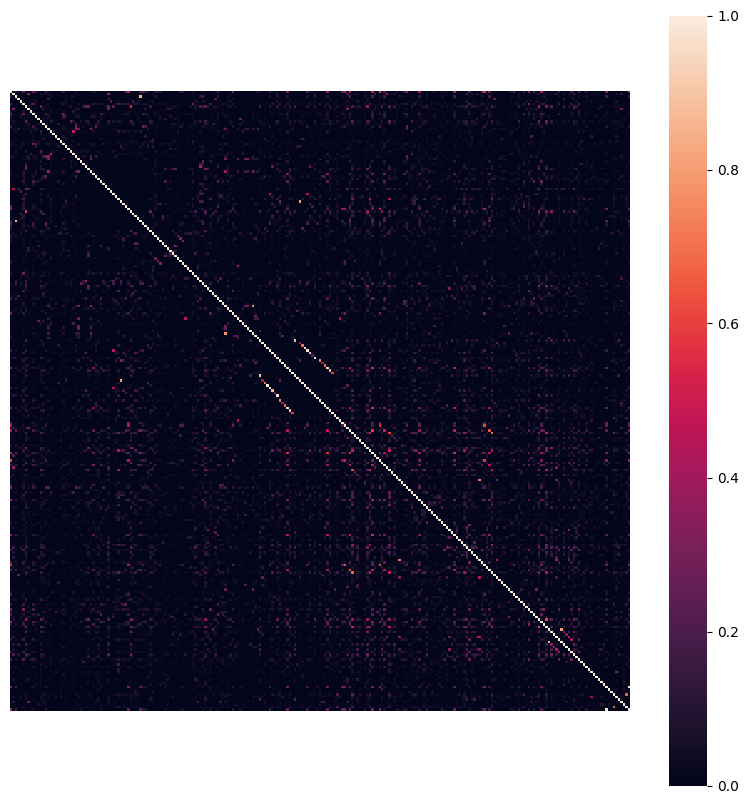

In [240]:
# Let's take a look at a correlation plot
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().round(2)
sns.heatmap(data=correlation_matrix, annot=False, vmin=0, vmax=1, square=True, xticklabels=False, yticklabels=False) ;



In [241]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False)

,SalePrice
SalePrice,1.00
Bsmt Qual_Ex,0.61
Exter Qual_TA,0.60
Kitchen Qual_Ex,0.56
Kitchen Qual_TA,0.54
...,...
Condition 2_RRAe,0.00
Exterior 2nd_BrkFace,0.00
Roof Style_Shed,0.00
Bsmt Exposure_Mn,0.00


<Axes: >

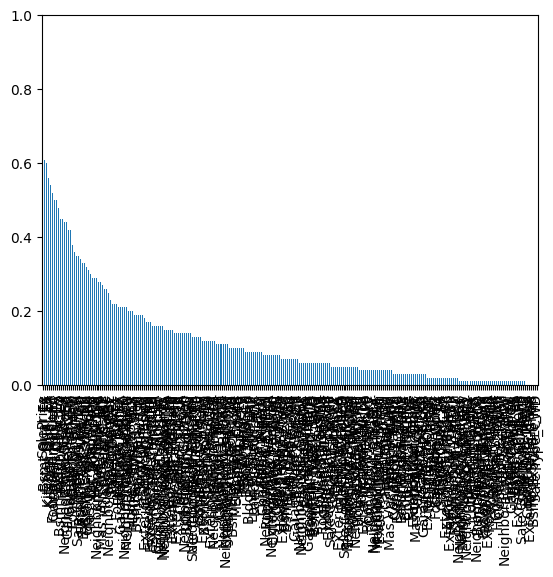

In [242]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False).plot( kind="bar", ylim = [0,1])

In [262]:
corrs = df.corr().round(2).unstack().abs()
corrs.reset_index()

,level_0,level_1,0
0,SalePrice,SalePrice,1.00
1,SalePrice,MS Zoning_C (all),0.10
2,SalePrice,MS Zoning_FV,0.10
3,SalePrice,MS Zoning_I (all),0.02
4,SalePrice,MS Zoning_RH,0.05
...,...,...,...
61996,Sale Condition_Partial,Sale Condition_AdjLand,0.01
61997,Sale Condition_Partial,Sale Condition_Alloca,0.02
61998,Sale Condition_Partial,Sale Condition_Family,0.04
61999,Sale Condition_Partial,Sale Condition_Normal,0.68


In [263]:
corrs = corrs[corrs < 1]
corrs.reset_index()

,level_0,level_1,0
0,SalePrice,MS Zoning_C (all),0.10
1,SalePrice,MS Zoning_FV,0.10
2,SalePrice,MS Zoning_I (all),0.02
3,SalePrice,MS Zoning_RH,0.05
4,SalePrice,MS Zoning_RL,0.23
...,...,...,...
61741,Sale Condition_Partial,Sale Condition_Abnorml,0.08
61742,Sale Condition_Partial,Sale Condition_AdjLand,0.01
61743,Sale Condition_Partial,Sale Condition_Alloca,0.02
61744,Sale Condition_Partial,Sale Condition_Family,0.04


In [283]:
my_list = []
for level_0, level_1 in corrs.index:
  if (level_1, level_0) not in my_list:
    my_list.append((level_0, level_1))

my_list[:10]

[('SalePrice', 'MS Zoning_C (all)'),
 ('SalePrice', 'MS Zoning_FV'),
 ('SalePrice', 'MS Zoning_I (all)'),
 ('SalePrice', 'MS Zoning_RH'),
 ('SalePrice', 'MS Zoning_RL'),
 ('SalePrice', 'MS Zoning_RM'),
 ('SalePrice', 'Street_Grvl'),
 ('SalePrice', 'Street_Pave'),
 ('SalePrice', 'Lot Shape_IR1'),
 ('SalePrice', 'Lot Shape_IR2')]

In [286]:
corrs[my_list].sort_values(ascending=False)

Sale Type_New         Sale Condition_Partial    0.98
Exterior 1st_VinylSd  Exterior 2nd_VinylSd      0.98
Exterior 1st_CemntBd  Exterior 2nd_CmentBd      0.98
Exterior 1st_MetalSd  Exterior 2nd_MetalSd      0.97
Mas Vnr Type_BrkFace  Mas Vnr Type_Stone        0.95
                                                ... 
Lot Config_FR2        Sale Type_COD             0.00
                      Fence_MnPrv               0.00
Mas Vnr Type_BrkCmn   Exter Cond_Po             0.00
Lot Config_FR2        Garage Qual_TA            0.00
Mas Vnr Type_BrkCmn   Bsmt Cond_Po              0.00
Length: 30873, dtype: float64

### What do we notice?

- SalePrice vs. Lot Frontage do not appear to be highly correlated to each other

In [ ]:
df.size

In [ ]:
# Let's plot a pairplot
sns.pairplot(df) ;



### What do we notice?

- After encoding, it is difficult to assess correlations visually among the different variables using a correlation matrix. To do this, we would likely need to cull redundant features first,

## Processing



## Data Visualization/Communication of Results
